# Week 1 — A universe, unevenly connected

Arnar · Birkir · Hanna

Question: does the most linked-to character keep the network connected? Frozen Marvel snapshot: 2026-08-26.

In [1]:
from pathlib import Path
import sys
import networkx as nx
from IPython.display import SVG, display
root = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
sys.path.insert(0, str(root / 'analysis'))
from build_week1 import load_graph, analyze, make_figure
G = load_graph()
result = analyze(G)
result['stats']

{'nodes': 303,
 'directedEdges': 1784,
 'undirectedEdges': 1434,
 'reciprocalPairs': 350,
 'isolates': 17,
 'components': 19,
 'giant': 277,
 'island': 9,
 'averageDegree': 9.465346534653465,
 'density': 0.03134220706838896,
 'afterSpiderMan': 271,
 'stranded': ['Enigma_(Marvel_Comics)',
  'Ethan_Edwards',
  'Helix_(Marvel_Comics)',
  'NFL_SuperPro',
  'Thunderclap_(comics)'],
 'zeroIn': 58,
 'zeroOut': 20}

## The two leaderboards

She-Hulk and U.S. Agent are tied at 20 outgoing links. Alphabetical ordering chooses She-Hulk for fifth place.

In [2]:
for title, degrees in [('Incoming', G.in_degree()), ('Outgoing', G.out_degree())]:
    print(title)
    for node, degree in sorted(degrees, key=lambda pair: (-pair[1], G.nodes[pair[0]]['name']))[:6]:
        print(G.nodes[node]['name'], degree)
    print()

Incoming
Spider-Man 106
Hulk 64
Wolverine (character) 60
Doctor Strange 50
Deadpool 33
She-Hulk 29

Outgoing
Betsy Braddock 28
Cloak and Dagger (characters) 24
Adam Warlock 22
Venom (character) 21
She-Hulk 20
U.S. Agent 20



## Where does the graph disconnect?

Components ignore direction. Being in one component does not guarantee directed reachability.

In [3]:
U = G.to_undirected()
components = sorted(nx.connected_components(U), key=len, reverse=True)
print('Component sizes:', [len(c) for c in components])
island = G.subgraph(components[1])
print('Island:', sorted(island))
print('Island directed edges:', island.number_of_edges())
print('Island undirected pairs:', island.to_undirected().number_of_edges())

Component sizes: [277, 9, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Island: ['Backhand_(character)', 'Blackthorn_(character)', 'Radian_(Morituri)', 'Scaredycat', 'Scatterbrain_(Morituri)', 'Shear_(character)', 'Snapdragon_(Morituri)', 'Toxyn', 'Vyking']
Island directed edges: 22
Island undirected pairs: 13


## Remove Spider-Man

We remove just this node from the original main component. This asks about connectivity, not how distances or directed paths change.

In [4]:
after = U.subgraph(components[0]).copy()
after.remove_node('Spider-Man')
after_components = sorted(nx.connected_components(after), key=len, reverse=True)
print('Before:', len(components[0]))
print('After:', [len(c) for c in after_components])
print('New isolates:', sorted(nx.isolates(after)))
assert len(after_components[0]) == 271

Before: 277
After: [271, 1, 1, 1, 1, 1]
New isolates: ['Enigma_(Marvel_Comics)', 'Ethan_Edwards', 'Helix_(Marvel_Comics)', 'NFL_SuperPro', 'Thunderclap_(comics)']


## Degree distributions

Plot against k + 1 so degree-zero pages remain visible. Mixed bins have width 1 through u = 7, then double. Each count is divided by 303 and its integer width. Width-1 agreement and total probability are checked inside analyze().

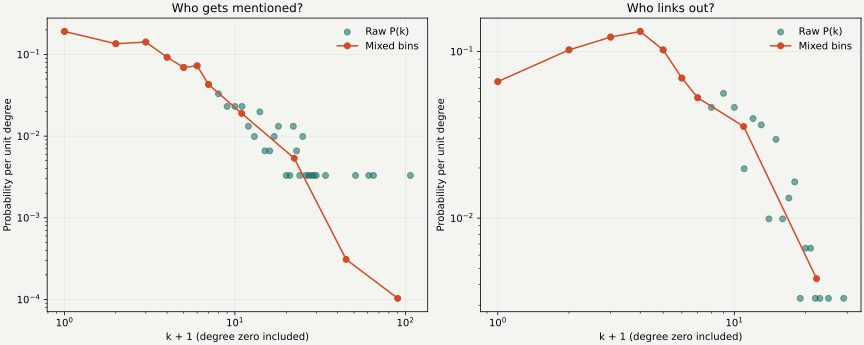

In [5]:
make_figure(G, result)
display(SVG(filename=str(root / 'site' / 'assets' / 'week1-degrees.svg')))

## Interpretation and limits

Spider-Man receives 106 incoming links, but 271 of the 276 other members of the main component remain connected after his removal. Five lose their only neighbor. The nine-node island and 17 isolates describe this collected graph, not all relationships between these characters.

The incoming tail is longer than the outgoing tail. A shifted, binned plot alone does not prove a power law.

[Course data](https://sunelehmann.com/socialgraphs2026-web/data/) · [Week 1](https://sunelehmann.com/socialgraphs2026-web/weeks/week1.html)